<a href="https://colab.research.google.com/github/samsyed004/public-transport-demand-management/blob/main/CV_ABM_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install ultralytics

In [2]:

from ultralytics import YOLO

# Pretrained model: no training required yet
model = YOLO("yolov8n.pt")

print("Computer Vision model loaded successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Computer Vision model loaded successfully!


In [5]:

from google.colab import files

uploaded = files.upload()
image_path = next(iter(uploaded))

print("Image uploaded:", image_path)

Saving 0000063_06000_d_0000007.jpg to 0000063_06000_d_0000007.jpg
Image uploaded: 0000063_06000_d_0000007.jpg


Detected people: 20


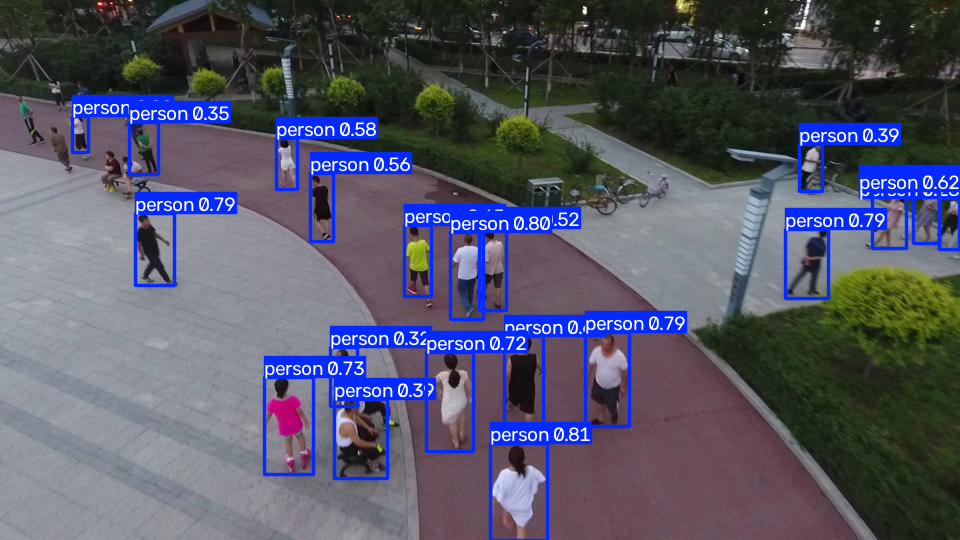

In [6]:

import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

# Run detection
results = model.predict(
    source=image_path,
    conf=0.25,
    verbose=False
)

result = results[0]

# COCO class 0 = person for this pretrained model
person_count = sum(
    1 for box in result.boxes
    if int(box.cls[0]) == 0
)

print("Detected people:", person_count)

# Display the image with detection boxes
annotated = result.plot()
display(Image.fromarray(annotated[:, :, ::-1]))

In [7]:

from google.colab import files

uploaded = files.upload()

Saving multiclass_ground_truth.zip to multiclass_ground_truth.zip


In [8]:
import zipfile
import os

zip_name = next(
    name for name in uploaded
    if name.lower().endswith(".zip")
)

extract_dir = "/content/epfl_dataset"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall(extract_dir)

print("Dataset extracted to:", extract_dir)

Dataset extracted to: /content/epfl_dataset


In [9]:
import os

for root, dirs, files_list in os.walk("/content/epfl_dataset"):
    level = root.replace("/content/epfl_dataset", "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    print("\nFolder:", root)

    for filename in files_list[:8]:
        print("  ", filename)


Folder: /content/epfl_dataset

Folder: /content/epfl_dataset/bounding_boxes_EPFL_cross

Folder: /content/epfl_dataset/bounding_boxes_EPFL_cross/gt_files242_bus

Folder: /content/epfl_dataset/bounding_boxes_EPFL_cross/gt_files242_bus/visible_frame
   det_frame214_cam5.txt
   det_frame197_cam0.txt
   det_frame82_cam5.txt
   det_frame81_cam0.txt
   det_frame213_cam0.txt
   det_frame214_cam4.txt
   det_frame198_cam3.txt
   det_frame213_cam2.txt

Folder: /content/epfl_dataset/bounding_boxes_EPFL_cross/gt_files242_car

Folder: /content/epfl_dataset/bounding_boxes_EPFL_cross/gt_files242_car/visible_frame
   det_frame223_cam5.txt
   det_frame166_cam5.txt
   det_frame214_cam5.txt
   det_frame23_cam2.txt
   det_frame173_cam2.txt
   det_frame104_cam5.txt
   det_frame73_cam5.txt
   det_frame229_cam3.txt

Folder: /content/epfl_dataset/bounding_boxes_EPFL_cross/gt_files242_person

Folder: /content/epfl_dataset/bounding_boxes_EPFL_cross/gt_files242_person/visible_frame
   det_frame223_cam5.txt
   de

In [10]:
import os

base = "/content/epfl_dataset/bounding_boxes_EPFL_cross"

person_dir = os.path.join(
    base,
    "gt_files242_person",
    "visible_frame"
)

# Read one annotation file
filename = os.listdir(person_dir)[0]
filepath = os.path.join(person_dir, filename)

print("File:", filename)
print("\nAnnotation contents:\n")

with open(filepath, "r") as f:
    for i, line in enumerate(f):
        print(line.strip())
        if i >= 9:
            break

File: det_frame223_cam5.txt

Annotation contents:

5.3949204e+01   7.2235618e+01   6.3819461e+01   1.1206916e+02


In [11]:
import os
import glob

person_files = glob.glob(
    os.path.join(person_dir, "*.txt")
)

print("Total person annotation files:", len(person_files))

for filepath in sorted(person_files)[:10]:
    with open(filepath, "r") as f:
        lines = [line.strip() for line in f if line.strip()]

    print(os.path.basename(filepath), "->", len(lines), "annotations")

Total person annotation files: 939
det_frame100_cam0.txt -> 1 annotations
det_frame100_cam1.txt -> 1 annotations
det_frame100_cam2.txt -> 1 annotations
det_frame100_cam3.txt -> 1 annotations
det_frame100_cam4.txt -> 1 annotations
det_frame100_cam5.txt -> 1 annotations
det_frame101_cam0.txt -> 1 annotations
det_frame101_cam1.txt -> 1 annotations
det_frame101_cam2.txt -> 1 annotations
det_frame101_cam3.txt -> 1 annotations


In [12]:
import os
import glob

person_dir = (
    "/content/epfl_dataset/"
    "bounding_boxes_EPFL_cross/"
    "gt_files242_person/visible_frame"
)

files = sorted(glob.glob(person_dir + "/*.txt"))

for path in files[:3]:
    print("\nFile:", os.path.basename(path))

    with open(path, "r") as f:
        content = f.read()

    print("Raw content:")
    print(repr(content[:1000]))


File: det_frame100_cam0.txt
Raw content:
'   1.1840638e+02   1.9025319e+02   1.4536809e+02   2.7113830e+02\n'

File: det_frame100_cam1.txt
Raw content:
'   2.2814894e+01   1.2775106e+02   4.3240426e+01   1.8371702e+02\n'

File: det_frame100_cam2.txt
Raw content:
'   1.4495957e+02   1.5307872e+02   1.6701915e+02   2.0414255e+02\n'


In [16]:
import os
import glob
import re
import pandas as pd

base = "/content/epfl_dataset/bounding_boxes_EPFL_cross"

folders = {
    "passenger_count": os.path.join(
        base, "gt_files242_person", "visible_frame"
    ),
    "bus_count": os.path.join(
        base, "gt_files242_bus", "visible_frame"
    ),
    "car_count": os.path.join(
        base, "gt_files242_car", "visible_frame"
    )
}

def read_counts(folder, count_name):
    rows = []

    for path in glob.glob(os.path.join(folder, "*.txt")):
        filename = os.path.basename(path)

        match = re.match(
            r"det_frame(\d+)_cam(\d+)\.txt$", filename
        )

        if not match:
            continue

        frame = int(match.group(1))
        camera = int(match.group(2))

        with open(path, "r") as f:
            lines = [line for line in f if line.strip()]

        rows.append({
            "frame": frame,
            "camera_id": camera,
            count_name: len(lines)
        })

    return pd.DataFrame(
        rows,
        columns=["frame", "camera_id", count_name]
    )

# Build the table using person annotations
df = read_counts(
    folders["passenger_count"], "passenger_count"
)

# Add bus and car annotations
for name in ["bus_count", "car_count"]:
    extra = read_counts(folders[name], name)

    df = df.merge(
        extra,
        on=["frame", "camera_id"],
        how="outer"
    )

# Fill missing annotations and format the output
count_columns = [
    "passenger_count", "bus_count", "car_count"
]

df[count_columns] = df[count_columns].fillna(0).astype(int)

df = df.sort_values(
    ["frame", "camera_id"]
).reset_index(drop=True)

output_file = "/content/passenger_demand.csv"
df.to_csv(output_file, index=False)

print("CSV successfully created!")
print("Total rows:", len(df))
display(df.head(10))

CSV successfully created!
Total rows: 1370


,frame,camera_id,passenger_count,bus_count,car_count
0,1,1,1,0,0
1,1,2,0,0,3
2,1,3,0,0,4
3,1,4,1,0,4
4,1,5,0,0,2
5,2,1,1,0,0
6,2,2,0,0,3
7,2,3,0,0,4
8,2,4,1,0,4
9,2,5,0,0,2


In [19]:
from google.colab import files

files.download("/content/passenger_demand.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
import pandas as pd

df = pd.read_csv("/content/passenger_demand.csv")

print("Total rows:", len(df))
print("\nTotal passengers counted:",
      df["passenger_count"].sum())

print("\nPassenger count by camera:")
print(
    df.groupby("camera_id")["passenger_count"]
      .agg(["sum", "mean", "max"])
)

print("\nMissing values:")
print(df.isnull().sum())

Total rows: 1370

Total passengers counted: 1302

Passenger count by camera:
           sum      mean  max
camera_id                    
0          212  1.070707    3
1          244  1.196078    4
2          174  0.719008    4
3          151  0.623967    3
4          290  1.198347    4
5          231  0.954545    4

Missing values:
frame              0
camera_id          0
passenger_count    0
bus_count          0
car_count          0
dtype: int64


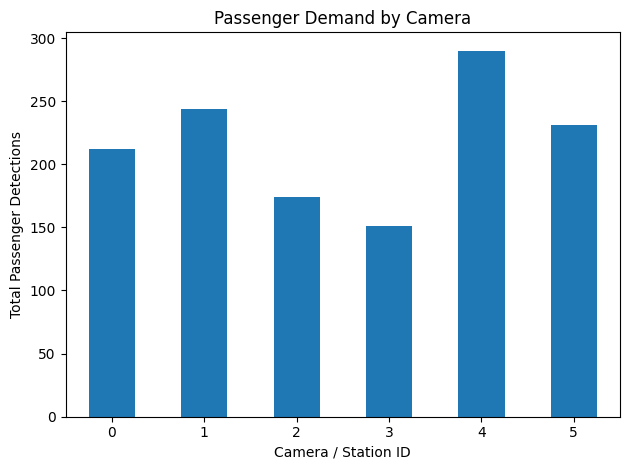

In [39]:
import matplotlib.pyplot as plt

demand = df.groupby("camera_id")["passenger_count"].sum()

demand.plot(kind="bar")
plt.title("Passenger Demand by Camera")
plt.xlabel("Camera / Station ID")
plt.ylabel("Total Passenger Detections")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [40]:
import pandas as pd

df = pd.read_csv("/content/passenger_demand.csv")

demand = (
    df.groupby("camera_id")["passenger_count"]
    .sum()
    .reset_index()
)

demand.columns = ["station_id", "total_detections"]

def classify_demand(count):
    if count >= 230:
        return "High"
    elif count >= 180:
        return "Medium"
    else:
        return "Low"

demand["demand_level"] = demand["total_detections"].apply(
    classify_demand
)

print(demand)

demand.to_csv("/content/station_demand.csv", index=False)
print("\nStation demand CSV saved!")

   station_id  total_detections demand_level
0           0               212       Medium
1           1               244         High
2           2               174          Low
3           3               151          Low
4           4               290         High
5           5               231         High

Station demand CSV saved!


In [25]:

from google.colab import files

uploaded = files.upload()

Saving berlin-apc.csv to berlin-apc.csv


In [26]:

import pandas as pd
import os

csv_file = next(
    name for name in uploaded
    if name.lower().endswith(".csv")
)

df = pd.read_csv(csv_file)

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 10 rows:")
display(df.head(10))

print("\nData types:")
print(df.dtypes)

Dataset shape: (12955, 3)

Column names:
['000000_000_01_06', '3', '0']

First 10 rows:


,000000_000_01_06,3,0
0,000001_000_01_07,0,2
1,000002_000_01_08,0,1
2,000003_000_01_09,1,0
3,000004_000_01_09,1,3
4,000005_000_01_09,1,0
5,000006_000_01_10,0,1
6,000007_000_01_10,2,1
7,000008_000_01_11,2,0
8,000009_000_01_11,5,1
9,000010_000_01_12,3,3



Data types:
000000_000_01_06    object
3                    int64
0                    int64
dtype: object


In [31]:

from google.colab import files
import os

os.makedirs("/content/dataset", exist_ok=True)

uploaded = files.upload()

video_files = [
    name for name in uploaded
    if name.lower().endswith((".mp4", ".avi", ".mov", ".mkv"))
]

if not video_files:
    raise ValueError("Please upload a video file.")

video_name = video_files[0]
video_path = os.path.join("/content/dataset", video_name)

with open(video_path, "wb") as f:
    f.write(uploaded[video_name])

print("Video saved at:", video_path)


Saving crosswalk.avi to crosswalk.avi
Video saved at: /content/dataset/crosswalk.avi


In [32]:

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise RuntimeError("Video could not be opened.")

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

duration = total_frames / fps if fps > 0 else 0

print("Video name:", video_name)
print("Resolution:", width, "x", height)
print("FPS:", fps)
print("Total frames:", total_frames)
print("Duration in seconds:", round(duration, 2))

cap.release()


Video name: crosswalk.avi
Resolution: 1920 x 1080
FPS: 30.0
Total frames: 0
Duration in seconds: 0.0


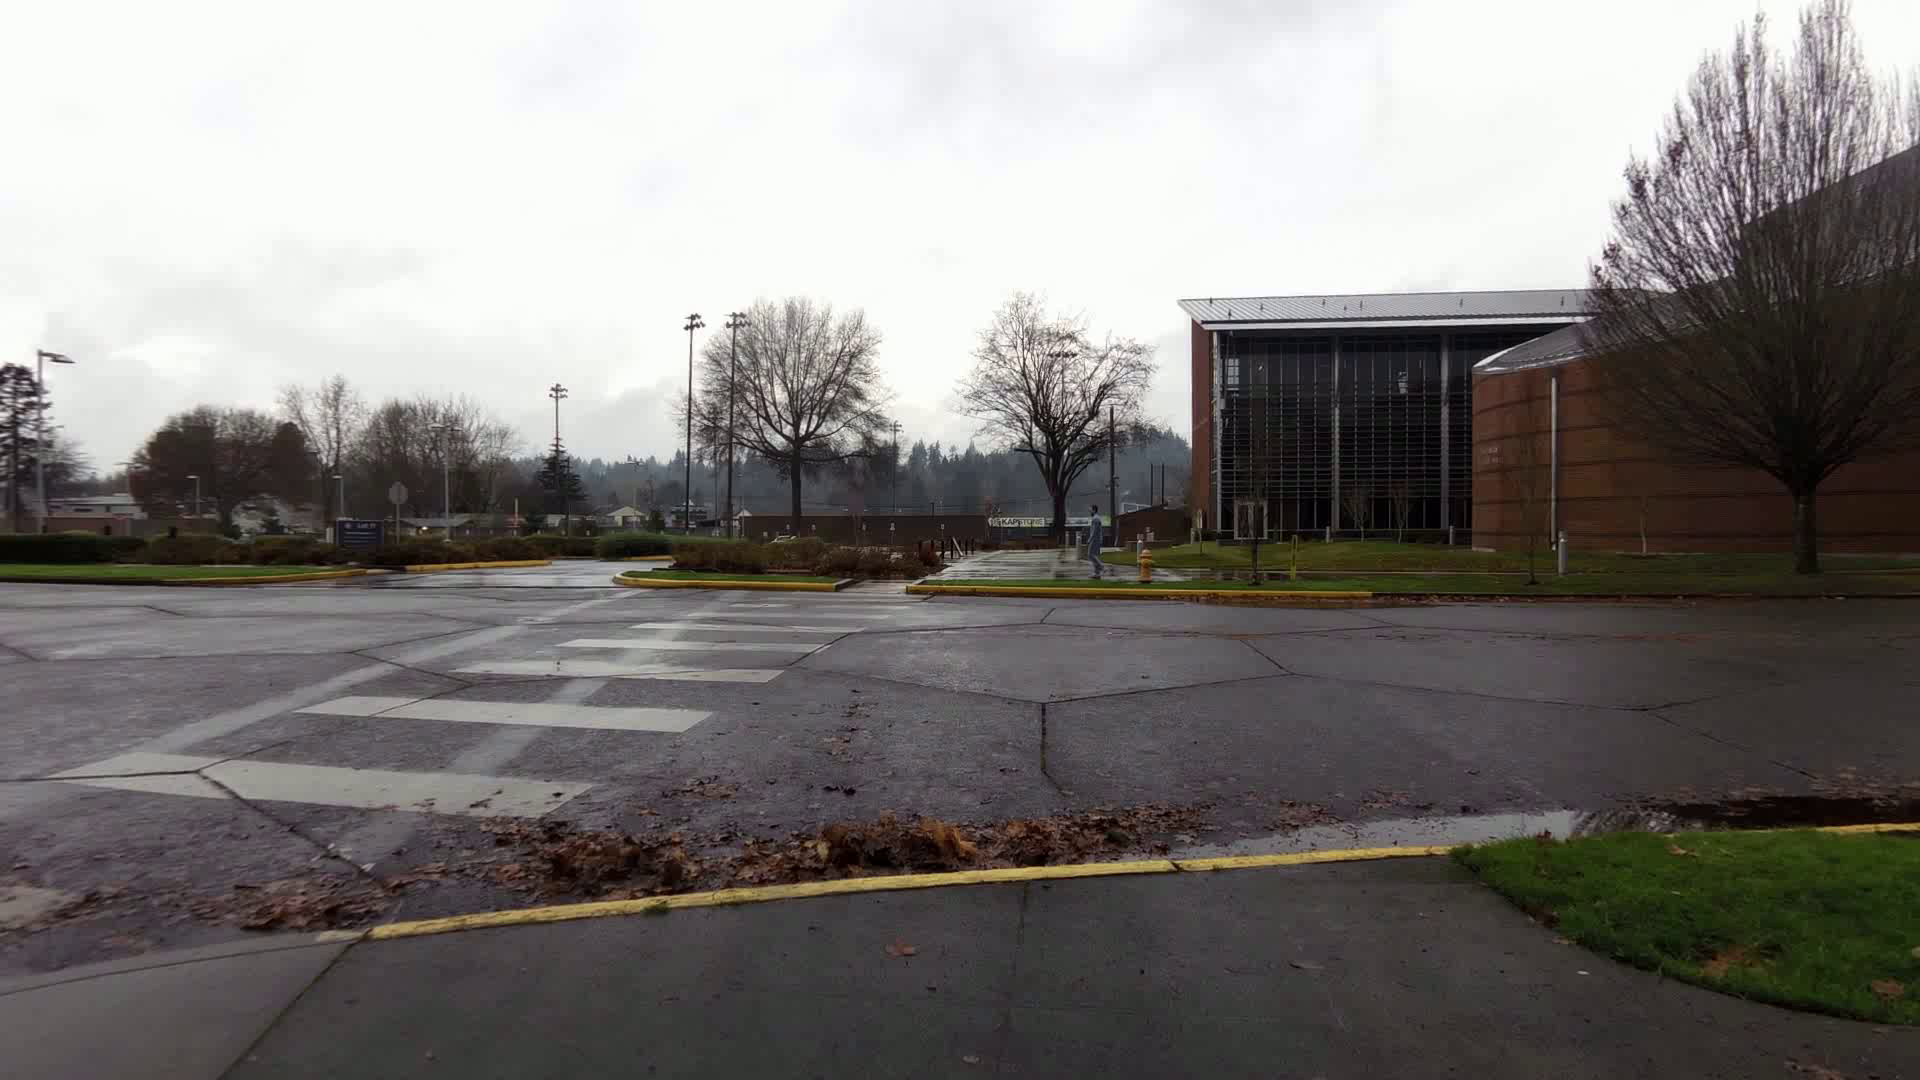

Detected objects:


In [33]:

from google.colab.patches import cv2_imshow

model = YOLO("yolo26n.pt")

cap = cv2.VideoCapture(video_path)
ret, frame = cap.read()
cap.release()

if not ret:
    raise RuntimeError("Could not read the first video frame.")

results = model.predict(
    source=frame,
    classes=[0, 5],
    conf=0.35,
    verbose=False
)

annotated_frame = results[0].plot()

cv2_imshow(annotated_frame)

print("Detected objects:")
for box in results[0].boxes:
    class_id = int(box.cls.item())
    label = results[0].names[class_id]
    confidence = float(box.conf.item())
    print(f"{label}: confidence = {confidence:.2f}")


In [35]:
!pip install opencv-python-headless

In [34]:
import cv2
import os
from pathlib import Path
from IPython.display import display, Image

# Find video files in the Colab content folder
video_extensions = [".mp4", ".avi", ".mov", ".mkv"]

video_files = [
    str(p) for p in Path("/content").iterdir()
    if p.suffix.lower() in video_extensions
]

print("Video files found:")
for i, file in enumerate(video_files):
    print(i, os.path.basename(file))

Video files found:
0 crosswalk.avi


In [36]:
video_path = video_files[0]  # Select the first video

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise ValueError("Could not open video. Check the file path.")

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

duration = total_frames / fps if fps > 0 else 0

print("Video:", os.path.basename(video_path))
print("Resolution:", width, "x", height)
print("FPS:", fps)
print("Total frames:", total_frames)
print("Duration:", round(duration, 2), "seconds")

Video: crosswalk.avi
Resolution: 1920 x 1080
FPS: 30.0
Total frames: 0
Duration: 0.0 seconds


In [37]:
import matplotlib.pyplot as plt

os.makedirs("/content/sample_frames", exist_ok=True)

if total_frames == 0:
    raise ValueError("The video contains no readable frames.")

sample_positions = [
    int(total_frames * fraction)
    for fraction in [0.05, 0.25, 0.50, 0.75, 0.95]
]

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for i, frame_number in enumerate(sample_positions):
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
    success, frame = cap.read()

    if success:
        # Save the frame
        frame_path = f"/content/sample_frames/frame_{i+1}.jpg"
        cv2.imwrite(frame_path, frame)

        # OpenCV uses BGR; Matplotlib uses RGB
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        axes[i].imshow(frame_rgb)
        axes[i].set_title(f"Frame {frame_number}")
    else:
        axes[i].set_title("Frame unavailable")

    axes[i].axis("off")

plt.tight_layout()
plt.show()

cap.release()

ValueError: The video contains no readable frames.